# 1 Khai báo thư viện và đọc dữ liệu

In [7]:
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)
!pip -q install mlxtend openpyxl

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth

%matplotlib inline


df = pd.read_excel('/content/Online Retail.xlsx')

print("\nThông tin dữ liệu ban đầu:")
df.info()

print("\n5 dòng dữ liệu đầu tiên:")
display(df.head())

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------

Thông tin dữ liệu ban đầu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

5 dòng dữ liệu đầu tiên:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


# 2 Làm sạch dữ liệu

In [8]:
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

df['Description'] = df['Description'].str.strip()

df.dropna(subset=['InvoiceNo'], inplace=True)

df['InvoiceNo'] = df['InvoiceNo'].astype(str)

print("5 dòng dữ liệu sau khi làm sạch:")
display(df.head())

print("\nThông tin dữ liệu sau khi làm sạch:")
df.info()

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
5 dòng dữ liệu sau khi làm sạch:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Thông tin dữ liệu sau khi làm sạch:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540454 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


# 3 Xử lý hóa đơn bị hủy

In [9]:

print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

print("Một số hóa đơn có ký tự C:")
display(df[df['InvoiceNo'].str.contains('C', na=False)].head(10))

df = df[~df['InvoiceNo'].str.contains('C', na=False)].copy()

print("\nSố dòng dữ liệu còn lại sau khi loại bỏ hóa đơn bị hủy:")
print(len(df))

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Một số hóa đơn có ký tự C:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom



Số dòng dữ liệu còn lại sau khi loại bỏ hóa đơn bị hủy:
532621


# 4 Thống kê số lượng theo quốc gia và vẽ biểu đồ

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Số lượng bản ghi theo quốc gia:


,Số lượng bản ghi
Country,
United Kingdom,487622
Germany,9042
France,8408
EIRE,7894
Spain,2485
Netherlands,2363
Belgium,2031
Switzerland,1967
Portugal,1501


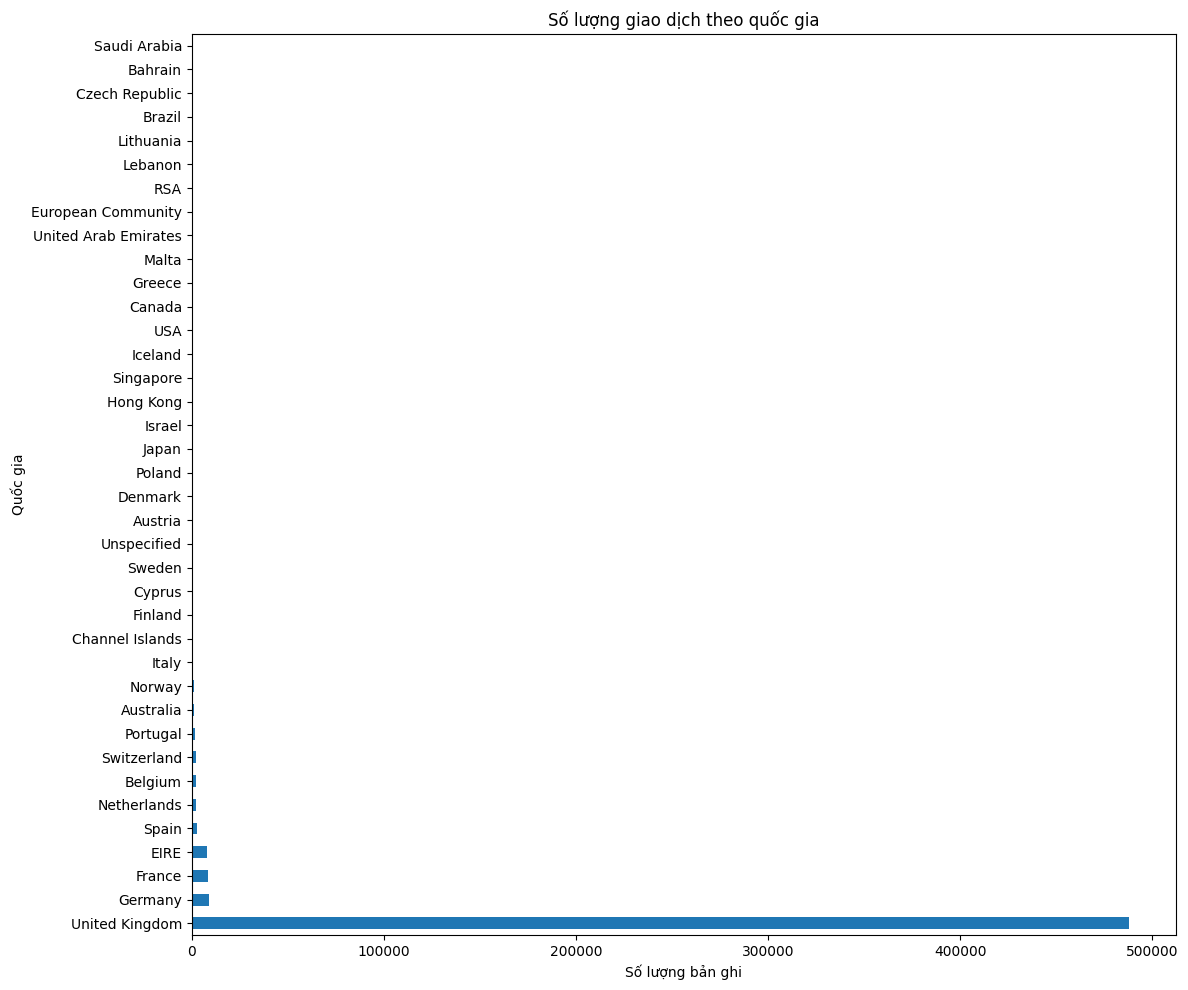

In [10]:
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

country_counts = df['Country'].value_counts()

print("Số lượng bản ghi theo quốc gia:")
display(country_counts.to_frame(name='Số lượng bản ghi'))

plt.figure(figsize=(12, 10))
country_counts.plot(kind='barh')

plt.title('Số lượng giao dịch theo quốc gia')
plt.xlabel('Số lượng bản ghi')
plt.ylabel('Quốc gia')
plt.tight_layout()
plt.show()

# 5 Lọc dữ liệu theo quốc gia Germany

In [11]:
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

df_germany = df[df['Country'] == 'Germany'].copy()

print("5 dòng dữ liệu tại Germany:")
display(df_germany.head())

print("\nSố lượng bản ghi tại Germany:", len(df_germany))
print("Số hóa đơn tại Germany:", df_germany['InvoiceNo'].nunique())

basket = df_germany.groupby(
    ['InvoiceNo', 'Description']
)['Quantity'].sum()

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
5 dòng dữ liệu tại Germany:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
1109,536527,22809,SET OF 6 T-LIGHTS SANTA,6,2010-12-01 13:04:00,2.95,12662.0,Germany
1110,536527,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,6,2010-12-01 13:04:00,2.55,12662.0,Germany
1111,536527,84945,MULTI COLOUR SILVER T-LIGHT HOLDER,12,2010-12-01 13:04:00,0.85,12662.0,Germany
1112,536527,22242,5 HOOK HANGER MAGIC TOADSTOOL,12,2010-12-01 13:04:00,1.65,12662.0,Germany
1113,536527,22244,3 HOOK HANGER MAGIC GARDEN,12,2010-12-01 13:04:00,1.95,12662.0,Germany



Số lượng bản ghi tại Germany: 9042
Số hóa đơn tại Germany: 457


# 6 Chuyển dữ liệu sang dạng giỏ hàng

In [12]:
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

basket = basket.unstack().reset_index().fillna(0)
basket = basket.set_index('InvoiceNo')

print("10 dòng đầu của bảng giỏ hàng:")
display(basket.head(10))

print("\nKích thước bảng giỏ hàng:")
print(basket.shape)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
10 dòng đầu của bảng giỏ hàng:


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY,12 PENCILS TALL TUBE RED RETROSPOT,12 PENCILS TALL TUBE SKULLS,...,YULETIDE IMAGES GIFT WRAP SET,ZINC HEART T-LIGHT HOLDER,ZINC STAR T-LIGHT HOLDER,ZINC BOX SIGN HOME,ZINC FOLKART SLEIGH BELLS,ZINC HEART LATTICE T-LIGHT HOLDER,ZINC METAL HEART DECORATION,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC WILLIE WINKIE CANDLE STICK
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536527,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536840,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536861,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536967,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536983,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537197,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537198,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537201,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537212,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Kích thước bảng giỏ hàng:
(457, 1695)


# 7 Chuyển đổi One-Hot Encoding

In [13]:
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)
def encode_data(quantity):
    if quantity <= 0:
        return 0
    else:
        return 1

basket = basket.applymap(encode_data)

print("10 dòng đầu sau khi chuyển đổi One-Hot Encoding:")
display(basket.head(10))

print("\nKích thước dữ liệu:", basket.shape)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
10 dòng đầu sau khi chuyển đổi One-Hot Encoding:


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY,12 PENCILS TALL TUBE RED RETROSPOT,12 PENCILS TALL TUBE SKULLS,...,YULETIDE IMAGES GIFT WRAP SET,ZINC HEART T-LIGHT HOLDER,ZINC STAR T-LIGHT HOLDER,ZINC BOX SIGN HOME,ZINC FOLKART SLEIGH BELLS,ZINC HEART LATTICE T-LIGHT HOLDER,ZINC METAL HEART DECORATION,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC WILLIE WINKIE CANDLE STICK
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536527,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536840,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536861,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536967,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536983,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537197,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537198,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537201,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537212,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Kích thước dữ liệu: (457, 1695)


# 8 Xóa cột POSTAGE

In [15]:
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)
if 'POSTAGE' in basket.columns:
    basket.drop(columns=['POSTAGE'], inplace=True)
    print("Đã xóa cột POSTAGE.")
else:
    print("Không tìm thấy cột POSTAGE, không cần xóa.")

print("\n10 dòng đầu sau khi xử lý:")
display(basket.head(10))

print("\nKích thước dữ liệu:", basket.shape)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Đã xóa cột POSTAGE.

10 dòng đầu sau khi xử lý:


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY,12 PENCILS TALL TUBE RED RETROSPOT,12 PENCILS TALL TUBE SKULLS,...,YULETIDE IMAGES GIFT WRAP SET,ZINC HEART T-LIGHT HOLDER,ZINC STAR T-LIGHT HOLDER,ZINC BOX SIGN HOME,ZINC FOLKART SLEIGH BELLS,ZINC HEART LATTICE T-LIGHT HOLDER,ZINC METAL HEART DECORATION,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC WILLIE WINKIE CANDLE STICK
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536527,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536840,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536861,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536967,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536983,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537197,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537198,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537201,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
537212,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Kích thước dữ liệu: (457, 1694)


# 9 Tìm tập phổ biến bằng Apriori

In [16]:
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)
min_sup = 0.05

itemsets = apriori(
    basket.astype(bool),
    min_support=min_sup,
    use_colnames=True
)

itemsets = itemsets.sort_values(
    by='support',
    ascending=False
).reset_index(drop=True)

print("Thuật toán Apriori")
print("min_sup =", min_sup)
print("Tổng số tập phổ biến:", len(itemsets))

display(itemsets.head(10))

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Thuật toán Apriori
min_sup = 0.05
Tổng số tập phổ biến: 59


,support,itemsets
0,0.245077,(ROUND SNACK BOXES SET OF4 WOODLAND)
1,0.157549,(ROUND SNACK BOXES SET OF 4 FRUITS)
2,0.137856,(PLASTERS IN TIN WOODLAND ANIMALS)
3,0.137856,(REGENCY CAKESTAND 3 TIER)
4,0.131291,"(ROUND SNACK BOXES SET OF4 WOODLAND, ROUND SNA..."
5,0.126915,(WOODLAND CHARLOTTE BAG)
6,0.115974,(PLASTERS IN TIN CIRCUS PARADE)
7,0.107221,(PLASTERS IN TIN SPACEBOY)
8,0.102845,(6 RIBBONS RUSTIC CHARM)
9,0.102845,(SPACEBOY LUNCH BOX)


# 10 Sinh luật kết hợp từ Apriori

In [17]:
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)
min_conf = 0.5

if len(itemsets) > 0:
    rules = association_rules(
        itemsets,
        metric='confidence',
        min_threshold=min_conf
    )

    rules = rules.sort_values(
        by='confidence',
        ascending=False
    ).reset_index(drop=True)

    print("min_conf =", min_conf)
    print("Tổng số luật kết hợp:", len(rules))

    print("\nThông tin bảng luật kết hợp:")
    rules.info()

    print("\n10 luật kết hợp đầu tiên:")
    display(
        rules[
            ['antecedents', 'consequents',
             'support', 'confidence', 'lift']
        ].head(10)
    )
else:
    rules = pd.DataFrame()
    print("Không có tập phổ biến thỏa mãn min_sup.")

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
min_conf = 0.5
Tổng số luật kết hợp: 8

Thông tin bảng luật kết hợp:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   antecedents         8 non-null      object 
 1   consequents         8 non-null      object 
 2   antecedent support  8 non-null      float64
 3   consequent support  8 non-null      float64
 4   support             8 non-null      float64
 5   confidence          8 non-null      float64
 6   lift                8 non-null      float64
 7   representativity    8 non-null      float64
 8   leverage            8 non-null      float64
 9   conviction          8 non-null      float64
 10  zhangs_metric       8 non-null      float64
 11  jaccard             8 non-null      float64
 12  certainty           8 non-null      float64
 13  kulczyns

,antecedents,consequents,support,confidence,lift
0,(RED RETROSPOT CHARLOTTE BAG),(WOODLAND CHARLOTTE BAG),0.059081,0.843750,6.648168
1,(ROUND SNACK BOXES SET OF 4 FRUITS),(ROUND SNACK BOXES SET OF4 WOODLAND),0.131291,0.833333,3.400298
2,(SPACEBOY LUNCH BOX),(ROUND SNACK BOXES SET OF4 WOODLAND),0.070022,0.680851,2.778116
3,(PLASTERS IN TIN CIRCUS PARADE),(PLASTERS IN TIN WOODLAND ANIMALS),0.067834,0.584906,4.242887
4,(PLASTERS IN TIN SPACEBOY),(PLASTERS IN TIN WOODLAND ANIMALS),0.061269,0.571429,4.145125
5,(PLASTERS IN TIN WOODLAND ANIMALS),(ROUND SNACK BOXES SET OF4 WOODLAND),0.074398,0.539683,2.202098
6,(ROUND SNACK BOXES SET OF4 WOODLAND),(ROUND SNACK BOXES SET OF 4 FRUITS),0.131291,0.535714,3.400298
7,(WOODLAND CHARLOTTE BAG),(ROUND SNACK BOXES SET OF4 WOODLAND),0.063457,0.500000,2.040179


# 11 Vẽ biểu đồ phân tán Scatter Plot

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


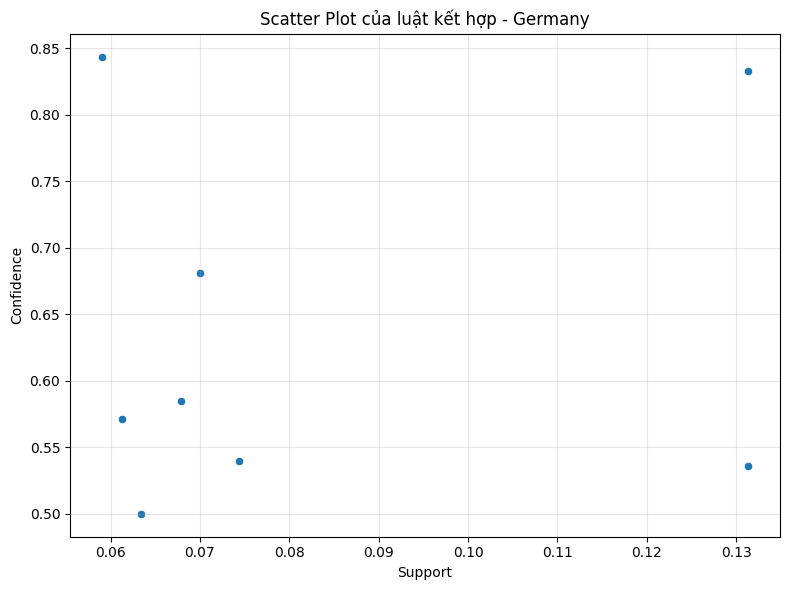

In [18]:
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)
if not rules.empty:
    plt.figure(figsize=(8, 6))

    sns.scatterplot(
        data=rules,
        x='support',
        y='confidence'
    )

    plt.title('Scatter Plot của luật kết hợp - Germany')
    plt.xlabel('Support')
    plt.ylabel('Confidence')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Không có luật kết hợp để vẽ biểu đồ.")

# 12 Tìm tập phổ biến và luật kết hợp bằng FP-Growth, so sánh kết quả

In [19]:
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)
itemsets_fpgrowth = fpgrowth(
    basket.astype(bool),
    min_support=0.05,
    use_colnames=True
)

itemsets_fpgrowth = itemsets_fpgrowth.sort_values(
    by='support',
    ascending=False
).reset_index(drop=True)

print("Kết quả FP-Growth")
print("min_sup = 0.05")
print("Tổng số tập phổ biến:", len(itemsets_fpgrowth))

display(itemsets_fpgrowth.head(10))

if len(itemsets_fpgrowth) > 0:
    rules_fpgrowth = association_rules(
        itemsets_fpgrowth,
        metric='confidence',
        min_threshold=0.5
    )

    rules_fpgrowth = rules_fpgrowth.sort_values(
        by='confidence',
        ascending=False
    ).reset_index(drop=True)

    print("\nTổng số luật kết hợp FP-Growth:", len(rules_fpgrowth))

    display(
        rules_fpgrowth[
            ['antecedents', 'consequents',
             'support', 'confidence', 'lift']
        ].head(10)
    )
else:
    rules_fpgrowth = pd.DataFrame()
    print("Không có tập phổ biến thỏa mãn min_sup.")

# So sánh các tập phổ biến
apriori_sets = set(
    itemsets['itemsets'].apply(frozenset)
)

fpgrowth_sets = set(
    itemsets_fpgrowth['itemsets'].apply(frozenset)
)

print("\nSo sánh Apriori và FP-Growth")
print("Số tập phổ biến Apriori:", len(apriori_sets))
print("Số tập phổ biến FP-Growth:", len(fpgrowth_sets))
print("Hai thuật toán cho cùng tập phổ biến:", apriori_sets == fpgrowth_sets)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Kết quả FP-Growth
min_sup = 0.05
Tổng số tập phổ biến: 59


,support,itemsets
0,0.245077,(ROUND SNACK BOXES SET OF4 WOODLAND)
1,0.157549,(ROUND SNACK BOXES SET OF 4 FRUITS)
2,0.137856,(REGENCY CAKESTAND 3 TIER)
3,0.137856,(PLASTERS IN TIN WOODLAND ANIMALS)
4,0.131291,"(ROUND SNACK BOXES SET OF4 WOODLAND, ROUND SNA..."
5,0.126915,(WOODLAND CHARLOTTE BAG)
6,0.115974,(PLASTERS IN TIN CIRCUS PARADE)
7,0.107221,(PLASTERS IN TIN SPACEBOY)
8,0.102845,(SPACEBOY LUNCH BOX)
9,0.102845,(6 RIBBONS RUSTIC CHARM)



Tổng số luật kết hợp FP-Growth: 8


,antecedents,consequents,support,confidence,lift
0,(RED RETROSPOT CHARLOTTE BAG),(WOODLAND CHARLOTTE BAG),0.059081,0.843750,6.648168
1,(ROUND SNACK BOXES SET OF 4 FRUITS),(ROUND SNACK BOXES SET OF4 WOODLAND),0.131291,0.833333,3.400298
2,(SPACEBOY LUNCH BOX),(ROUND SNACK BOXES SET OF4 WOODLAND),0.070022,0.680851,2.778116
3,(PLASTERS IN TIN CIRCUS PARADE),(PLASTERS IN TIN WOODLAND ANIMALS),0.067834,0.584906,4.242887
4,(PLASTERS IN TIN SPACEBOY),(PLASTERS IN TIN WOODLAND ANIMALS),0.061269,0.571429,4.145125
5,(PLASTERS IN TIN WOODLAND ANIMALS),(ROUND SNACK BOXES SET OF4 WOODLAND),0.074398,0.539683,2.202098
6,(ROUND SNACK BOXES SET OF4 WOODLAND),(ROUND SNACK BOXES SET OF 4 FRUITS),0.131291,0.535714,3.400298
7,(WOODLAND CHARLOTTE BAG),(ROUND SNACK BOXES SET OF4 WOODLAND),0.063457,0.500000,2.040179



So sánh Apriori và FP-Growth
Số tập phổ biến Apriori: 59
Số tập phổ biến FP-Growth: 59
Hai thuật toán cho cùng tập phổ biến: True
